In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from scipy.stats import norm, chi2, skew, kurtosis, kstest,ks_2samp, ttest_ind,spearmanr
import shap
from scipy.optimize import minimize
import statsmodels.api as sm
import statsmodels.formula.api as smf
from arch import arch_model
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_white, acorr_ljungbox, het_arch
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    roc_auc_score, 
    confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
%matplotlib inline
import logging
logging.getLogger("tqdm").setLevel(logging.ERROR)
import xlsxwriter

C:\Users\PC\anaconda3\envs\research_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
start_date= "2000-01-01"
end_date= "2025-10-30"
sp = yf.download("BTC-USD", start=start_date, end=end_date)['Close']
sp_ret = np.log(sp).diff().dropna()
tickers = ["^VIX", "SPY", "TLT", "HYG"]
data = yf.download(tickers, start=start_date, end=end_date)["Close"].ffill()


alphas = [0.005, 0.003,0.01]
rolling_window = 252 * 5
forecast_horizons = [1, 5, 10, 21]

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  4 of 4 completed


<Figure size 800x500 with 0 Axes>

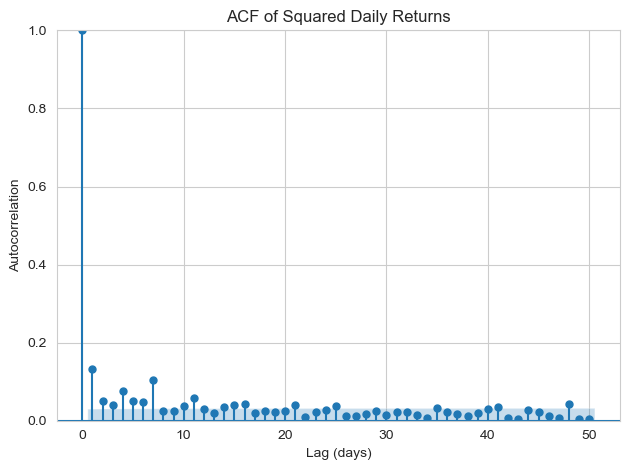

In [3]:
rets = sp_ret.dropna()
abs_ret = np.abs(rets)
sq_ret  = rets**2

plt.figure(figsize=(8, 5))
plot_acf(sq_ret, lags=50)
plt.title("ACF of Squared Daily Returns")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(0, 1) 
plt.tight_layout()
plt.show()

In [4]:
def rolling_var_monthly(returns, alphas, rolling_window, forecast_horizons,
                        start_date, end_date, regime_name):

    
    if isinstance(returns, pd.DataFrame):
        if returns.shape[1] > 1:
            raise ValueError("Returns must be a single-column Series or DataFrame.")
        returns = returns.iloc[:, 0]

    returns = returns.sort_index()
    idx = returns.index

    start_date = pd.to_datetime(start_date)
    end_date   = pd.to_datetime(end_date)

    out = []

    
    for i in range(rolling_window - 1, len(idx) - max(forecast_horizons)):

        window_end   = idx[i]
        window_start = idx[i - rolling_window + 1]
        r_win = returns.iloc[i - rolling_window + 1: i + 1]

        
        if len(r_win) < 200:
            continue

        
        mu = float(r_win.mean())
        sigma = float(r_win.std(ddof=1))

        std_resid = (r_win - mu) / sigma
        std_resid = std_resid.values  
        
        for h in forecast_horizons:

            if i + h >= len(idx):
                continue

            var_date = idx[i + h]

            if not (start_date <= var_date <= end_date):
                continue

            
            mu_h  = mu * h
            sig_h = sigma * np.sqrt(h)

            
            actual_val = returns.loc[var_date]
            actual = float(actual_val)

        
            for a in alphas:

               
                q_alpha = np.quantile(std_resid, a)
                var_fhs = float(mu_h + sig_h * q_alpha)

                
                k = np.sqrt((1 - a) / a)
                var_cant = float(mu_h - k * sig_h)

                model_name = f"{regime_name}_{a}_{h}"

                out.append({
                    "ModelName": model_name,
                    "Alpha": a,
                    "ForecastHorizon": h,
                    "VaR_Estimation_Date": var_date,
                    "RollingStart": window_start,
                    "RollingEnd": window_end,
                    "FHS_VaR": var_fhs,
                    "Cantelli_VaR": var_cant,
                    "ActualReturn": actual,
                    "VaR_Ratio": var_fhs / var_cant,
                    "Breach_FHS": int(actual < var_fhs),
                    "Breach_CCantelli": int(actual < var_cant),
                    "Regime": regime_name
                })

    df = pd.DataFrame(out)
    df.sort_values(["VaR_Estimation_Date", "ForecastHorizon", "Alpha"], inplace=True)
    df.reset_index(drop=True, inplace=True)
    return df


In [5]:
df_full = rolling_var_monthly(sp_ret, alphas, rolling_window, forecast_horizons,
                              "2007-10-01", "2025-10-30", "FullSample")

df_covid  = rolling_var_monthly(sp_ret, alphas, rolling_window, forecast_horizons,
                                "2020-01-01", "2020-12-31", "COVID")

df_infl   = rolling_var_monthly(sp_ret, alphas, rolling_window, forecast_horizons,
                                "2022-01-01", "2022-12-31", "Inflation")

In [6]:
def run_breach_models_with_newey_west(df, scope_name, max_lags=None):

    results = []

    for (alpha, h), sub in df.groupby(["Alpha", "ForecastHorizon"]):

        sub = sub.dropna(subset=["VaR_Ratio", "Breach_FHS"])
        if sub["Breach_FHS"].nunique() < 2:
            continue

        X = sm.add_constant(sub["VaR_Ratio"])
        y = sub["Breach_FHS"]

        try:
            logit_m = sm.Logit(y, X).fit(cov_type='HAC', 
                                         cov_kwds={'maxlags': max_lags},
                                         disp=False)
            probit_m = sm.Probit(y, X).fit(cov_type='HAC', 
                                           cov_kwds={'maxlags': max_lags},
                                           disp=False)

            logit_p = logit_m.predict(X)
            probit_p = probit_m.predict(X)

            auc_logit = roc_auc_score(y, logit_p)
            auc_probit = roc_auc_score(y, probit_p)

            results.append({
                "Scope": scope_name,
                "Alpha": alpha,
                "ForecastHorizon": h,
                "Obs": len(sub),

                "Logit_Beta_Ratio": round(logit_m.params["VaR_Ratio"], 2),
                "Logit_p_NeweyWest": round(logit_m.pvalues["VaR_Ratio"], 2),
                
                "AUC_Logit": round(auc_logit, 2),
                "AR_Logit": round(2 * auc_logit - 1, 2),

                
            })

        except:
            continue

    return pd.DataFrame(results)


def run_robustness_analysis(df, scope_name):
    lag_specs = [None, 5, 10, 22]
    out = []
    for L in lag_specs:
        r = run_breach_models_with_newey_west(df, scope_name, max_lags=L)
        if not r.empty:
            out.append(r)
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame()

res_full_nw  = run_breach_models_with_newey_west(df_full,  "FullSample", max_lags=10)
res_covid_nw  = run_breach_models_with_newey_west(df_covid,  "COVID", max_lags=5)
res_infl_nw   = run_breach_models_with_newey_west(df_infl,   "Inflation", max_lags=5)

final_nw = pd.concat([res_full_nw, res_covid_nw, res_infl_nw], ignore_index=True)


final_nw

,Scope,Alpha,ForecastHorizon,Obs,Logit_Beta_Ratio,Logit_p_NeweyWest,AUC_Logit,AR_Logit
0,FullSample,0.003,1,2780,-133.93,0.03,0.76,0.52
1,FullSample,0.003,5,2780,-65.16,0.00,0.63,0.26
2,FullSample,0.005,1,2780,-56.42,0.01,0.70,0.41
3,FullSample,0.005,5,2780,-36.18,0.00,0.66,0.33
4,FullSample,0.005,10,2780,-40.50,0.00,0.65,0.30
5,FullSample,0.010,1,2780,-46.29,0.00,0.68,0.35
6,FullSample,0.010,5,2780,-5.62,0.21,0.53,0.06
7,FullSample,0.010,10,2780,-9.78,0.03,0.55,0.11
8,COVID,0.003,1,366,443.23,0.00,0.81,0.62
9,COVID,0.003,5,366,548.66,0.00,0.81,0.61
